# CICIoT2023 Feature-Augmented GRU — Five-Seed Final Evaluation

## 1. Environment and reproducibility


In [1]:
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time
from tensorflow.keras.regularizers import l2

## 2. Load preprocessed data and feature-augmented data data 

The cells below retain the original preprocessing order and diagnostic outputs.


### Directly clean Augmented data 


In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())


Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [4]:
# ============================================================
# Dataset validation + feature-ablation configuration
# ============================================================

# Name of the target column used throughout the notebook.
LABEL_COLUMN = "label"

# ------------------------------------------------------------
# Anomaly-score features used by the FA configuration
# ------------------------------------------------------------
ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# ============================================================
# Select the ablation configuration
# ============================================================

# Change ONLY this line when running a different ablation.
#
# Available configurations:
#
# "Full_FA"
#     Original traffic features
#     + IF_Anomaly_Score
#     + AE_Anomaly_Score
#     + SUOD_Anomaly_Score
#
# "No_FA"
#     Original traffic features only.
#     All three anomaly-score features are removed.
#
# "IF_only"
#     Original traffic features
#     + IF_Anomaly_Score
#
# "AE_only"
#     Original traffic features
#     + AE_Anomaly_Score
#
# "SUOD_only"
#     Original traffic features
#     + SUOD_Anomaly_Score

ABLATION_MODE = "No_FA"

# ============================================================
# Validate the originally loaded augmented datasets
# ============================================================

# The same train, validation, and test partitions are used for
# every ablation configuration. Only the selected anomaly-score
# columns are removed. Samples, labels, and split membership
# therefore remain identical across configurations.

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )

# ============================================================
# Determine which anomaly-score features should be removed
# ============================================================

if ABLATION_MODE == "Full_FA":

    # Keep all three anomaly-score features.
    features_to_drop = []

elif ABLATION_MODE == "No_FA":

    # Remove all three anomaly-score features.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":

    # Keep only the Isolation Forest anomaly score.
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":

    # Keep only the Autoencoder reconstruction score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":

    # Keep only the SUOD ensemble anomaly score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:
    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use one of: Full_FA, No_FA, IF_only, "
        "AE_only, or SUOD_only."
    )

# ============================================================
# Apply the selected ablation
# ============================================================

# Only the selected anomaly-score columns are removed.
# No instances or labels are modified.

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()

# ============================================================
# Rebuild the feature list after ablation
# ============================================================

feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

# ============================================================
# Validate feature consistency across all partitions
# ============================================================

validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns do not match "
        "after applying the ablation configuration."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns do not match "
        "after applying the ablation configuration."
    )

# ============================================================
# Confirm which anomaly-score features remain
# ============================================================

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

# ============================================================
# Print experiment summary
# ============================================================

print("=" * 60)
print("Feature-ablation configuration")
print("=" * 60)

print(f"Ablation mode: {ABLATION_MODE}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Kept anomaly-score features: {kept_anomaly_features}")
print(f"Dropped anomaly-score features: {features_to_drop}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")

print("=" * 60)


Feature-ablation configuration
Ablation mode: No_FA
Number of input features: 32
Kept anomaly-score features: []
Dropped anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246


### Separate augmented features and multiclass labels


In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (354737, 32)
Validation features: (118246, 32)
Test features:       (118246, 32)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels


In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Standardize the augmented features


In [7]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on augmented training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train
).astype(np.float32)


# Apply the same fitted scaler without refitting
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data
# ============================================================
if not np.isfinite(X_train_scaled).all():
    raise ValueError(
        "Scaled training features contain invalid values."
    )

if not np.isfinite(X_val_scaled).all():
    raise ValueError(
        "Scaled validation features contain invalid values."
    )

if not np.isfinite(X_test_scaled).all():
    raise ValueError(
        "Scaled test features contain invalid values."
    )


print(f"Scaled training features:   {X_train_scaled.shape}")
print(f"Scaled validation features: {X_val_scaled.shape}")
print(f"Scaled test features:       {X_test_scaled.shape}")

print(
    f"\nTraining mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled training features:   (354737, 32)
Scaled validation features: (118246, 32)
Scaled test features:       (118246, 32)

Training mean after scaling: 0.000000
Training standard deviation after scaling: 1.000000


## 3. Gated Recurrent Unit Network (GRU)

### Prepare the GRU input representation

In [8]:
# Preserve the original one-time-step representation, using scaled inputs.
input_attribute_count = X_train_scaled.shape[1]

X_train_reshaped_GRU = X_train_scaled.reshape(
    -1, 1, input_attribute_count
)
X_val_reshaped_GRU = X_val_scaled.reshape(
    -1, 1, input_attribute_count
)
X_test_reshaped_GRU = X_test_scaled.reshape(
    -1, 1, input_attribute_count
)

print(f"GRU training shape:   {X_train_reshaped_GRU.shape}")
print(f"GRU validation shape: {X_val_reshaped_GRU.shape}")
print(f"GRU test shape:       {X_test_reshaped_GRU.shape}")


GRU training shape:   (354737, 1, 32)
GRU validation shape: (118246, 1, 32)
GRU test shape:       (118246, 1, 32)


### Optional GRU hyperparameter optimization

The original GRU Optuna structure is retained for future use.

- Keep `RUN_OPTUNA = False` for the current 5-seed final experiment.
  The previously stored optimized GRU parameters are loaded.
- Change `RUN_OPTUNA = True` only when you want to perform a new
  hyperparameter search.

The optimization uses the training and validation partitions only.
The test partition is not used for hyperparameter selection.


In [9]:
# ============================================================
# GRU optimization control
# ============================================================

import json
import os

# False -> use previously stored optimized parameters.
# True  -> run a new Optuna search and save new parameters.
RUN_OPTUNA = False

N_OPTUNA_TRIALS = 25


# ------------------------------------------------------------
# Existing optimized parameters
# Kaggle input directories are read-only.
# ------------------------------------------------------------
PRESTORED_PARAMS_GRU_FILE = (
    "/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_gru_imbalanceCICIoT2023.json"
)


# ------------------------------------------------------------
# Newly optimized parameters
# Kaggle working directory is writable.
# ------------------------------------------------------------
NEW_PARAMS_GRU_FILE = (
    "/kaggle/working/"
    "best_params_gru_imbalanceCIC2023.json"
)


print(
    "RUN_OPTUNA:",
    RUN_OPTUNA,
)

print(
    "Number of Optuna trials:",
    N_OPTUNA_TRIALS,
)

if RUN_OPTUNA:
    print(
        "New optimized GRU parameters will be saved to:",
        NEW_PARAMS_GRU_FILE,
    )
else:
    print(
        "Pre-stored GRU parameters will be loaded from:",
        PRESTORED_PARAMS_GRU_FILE,
    )


RUN_OPTUNA: False
Number of Optuna trials: 25
Pre-stored GRU parameters will be loaded from: /kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_gru_imbalanceCICIoT2023.json


In [10]:
from sklearn.metrics import f1_score
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (
    GRU,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [11]:
# ============================================================
# Recommended GRU Optuna objective and search space
# ============================================================

MAX_EPOCHS_GRU = 100
EARLY_STOPPING_PATIENCE = 10


def objective_gru(trial):
    """Train one GRU trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    # --------------------------------------------------------
    # Architecture-specific recurrent-unit search space
    # --------------------------------------------------------
    hidden_layer1_gru = trial.suggest_int(
        "hidden_layer1_gru",
        32,
        128,
        step=16,
    )

    hidden_layer2_gru = trial.suggest_int(
        "hidden_layer2_gru",
        16,
        64,
        step=16,
    )

    # --------------------------------------------------------
    # Shared optimization search space
    # --------------------------------------------------------
    dropout_rate_gru = trial.suggest_float(
        "dropout_rate_gru",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg_gru = trial.suggest_float(
        "l2_reg_gru",
        1e-6,
        1e-3,
        log=True,
    )

    batch_size_gru = trial.suggest_categorical(
        "batch_size_gru",
        [64, 128, 256],
    )

    learning_rate_gru = trial.suggest_float(
        "learning_rate_gru",
        1e-5,
        1e-2,
        log=True,
    )

    model_gru_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),

            GRU(
                hidden_layer1_gru,
                return_sequences=True,
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            GRU(
                hidden_layer2_gru,
                return_sequences=False,
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),
        ],
        name="GRU_Optuna_Trial",
    )

    model_gru_trial.compile(
        loss="sparse_categorical_crossentropy",

        optimizer=Adam(
            learning_rate=(
                learning_rate_gru
            )
        ),

        metrics=[
            "accuracy",

            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    model_gru_trial.fit(
        X_train_reshaped_GRU,
        y_train,

        epochs=MAX_EPOCHS_GRU,

        batch_size=batch_size_gru,

        validation_data=(
            X_val_reshaped_GRU,
            y_val,
        ),

        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),

            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],

        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_gru_trial.predict(
            X_val_reshaped_GRU,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,

        labels=np.arange(
            number_of_classes
        ),

        average="macro",
        zero_division=0,
    )

    del model_gru_trial

    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [13]:
# !pip install optuna-integration[keras]

In [14]:
# ============================================================
# Execute optional Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    # Current Optuna versions provide integrations through
    # optuna-integration. The fallback supports older versions.
    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_gru = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_gru.optimize(
        objective_gru,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best GRU hyperparameters:",
        study_gru.best_params,
    )

    print(
        "Best GRU validation macro F1: "
        f"{study_gru.best_value:.6f}"
    )

    print(
        "GRU study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_gru.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_gru
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_gru
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_gru
        ),
    )

    best_trial_gru = (
        study_gru.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_gru.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_gru.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original variable name.
    best_params_gru_03_TVTF_SUDO_V3 = (
        study_gru.best_params
    )

    with open(
        NEW_PARAMS_GRU_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_gru_03_TVTF_SUDO_V3,
            json_file,
            indent=2,
        )

    print(
        "New optimized GRU parameters saved to:",
        NEW_PARAMS_GRU_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored GRU parameters."
    )


Optuna optimization skipped. Using the pre-stored GRU parameters.


### Load the optimized GRU parameters for final training

In [15]:
import json

# ============================================================
# Select and load GRU hyperparameters for final training
# ============================================================

PARAMS_GRU_FILE_TO_LOAD = (
    NEW_PARAMS_GRU_FILE
    if RUN_OPTUNA
    else PRESTORED_PARAMS_GRU_FILE
)

with open(
    PARAMS_GRU_FILE_TO_LOAD,
    "r",
    encoding="utf-8",
) as f:
    loaded_params = json.load(f)

# Supports both a direct parameter dictionary and a wrapped
# optimization record containing a "best_params" entry.
best_params_gru_03 = loaded_params.get(
    "best_params",
    loaded_params
)

print(
    "Loaded GRU hyperparameters from:"
)

print(
    PARAMS_GRU_FILE_TO_LOAD
)

print(
    "Loaded GRU hyperparameters:"
)

print(
    best_params_gru_03
)


Loaded GRU hyperparameters from:
/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_gru_imbalanceCICIoT2023.json
Loaded GRU hyperparameters:
{'hidden_layer1_gru': 128, 'hidden_layer2_gru': 32, 'dropout_rate_gru': 0.2, 'l2_reg_gru': 1.1321021804230381e-06, 'batch_size_gru': 64, 'learning_rate_gru': 0.0011769044926591633}


## 4. Five-run final training and journal reporting

The original five-run variables and evaluation logic are retained wherever
possible. `RUN_SEEDS` is set to five seeds (42–46). Dataset
partitions and the pre-stored optimized GRU hyperparameters remain fixed
across all runs.

In [16]:
from pathlib import Path
import gc

from tensorflow.keras import regularizers
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]
N_FINAL_RUNS = len(RUN_SEEDS)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 5

REPORT_OUTPUT_DIRECTORY = (
    Path.cwd()
    / f"CICIoT2023_{ABLATION_MODE}_GRU_5_seed_results"
)

# Keep the original variable name for compatibility.
# Each GRU_Seed_* folder is created directly inside this directory.
MODEL_OUTPUT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Request deterministic TensorFlow kernels when supported.
try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except (AttributeError, RuntimeError):
    print(
        "TensorFlow deterministic-operation control is unavailable "
        "in this environment."
    )


def benchmark_full_test_prediction(model, X_input):
    """Return probabilities and timing from the original inference protocol."""
    warmup_size = min(1024, len(X_input))

    for _ in range(N_WARMUP_RUNS):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(N_BENCHMARK_RUNS):
        start_time = time.perf_counter()

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter() - start_time
        )

    mean_inference_time = float(
        np.mean(measured_times)
    )

    return (
        probabilities,
        {
            "Inference_Time_s": mean_inference_time,
            "Latency_ms_per_sample": (
                mean_inference_time / len(X_input) * 1000.0
            ),
            "Throughput_samples_per_s": (
                len(X_input) / mean_inference_time
            ),
        },
        measured_times,
    )


def calculate_fpr_metrics(y_true, y_pred, labels):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""
    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        true_negative, false_positive, _, _ = matrix.ravel()

        denominator = (
            false_positive + true_negative
        )

        per_class_fpr.append(
            false_positive / denominator
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            false_positives.sum()
            / micro_denominator
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent GRU training run."""
    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Precision_macro": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Recall_macro": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "Recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "F1_weighted": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred,
        ),
    }

    try:
        metrics["ROC_AUC_macro_OvR"] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics["ROC_AUC_macro_OvR"] = np.nan
        print(
            f"Macro ROC-AUC could not be calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(mean_value, sd_value):
    """Create the journal-table mean ± sample-SD representation."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return f"{mean_value:.6f} ± NA"

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )
    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


TensorFlow deterministic operations enabled.


In [17]:
# ============================================================
# Save reproducibility artifacts for later offline inference
# ============================================================

import json
import joblib
import platform
import sys
import sklearn

# Save the exact classifier scaler used for this experiment.
joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY
    / "classifier_scaler.joblib",
)

# Save the exact feature order presented to the classifier.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "feature_columns.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        list(feature_columns),
        json_file,
        indent=2,
    )

# Save the encoded class order.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "class_names.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        label_encoder.classes_.tolist(),
        json_file,
        indent=2,
    )

# Save the exact GRU test tensor and labels used for inference.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy",
    X_test_reshaped_GRU,
)

np.save(
    REPORT_OUTPUT_DIRECTORY
    / "y_test.npy",
    y_test,
)

# Save the selected hyperparameters used by the final models.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        best_params_gru_03,
        json_file,
        indent=2,
    )

# Save the experiment configuration and software environment.
environment_metadata = {
    "Model": "GRU",
    "Ablation_Mode": ABLATION_MODE,
    "Kept_Anomaly_Features": kept_anomaly_features,
    "Dropped_Anomaly_Features": features_to_drop,
    "Python": sys.version,
    "TensorFlow": tf.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit_learn": sklearn.__version__,
    "Platform": platform.platform(),
    "Processor": platform.processor(),
    "Machine": platform.machine(),
    "Visible_TensorFlow_Devices": [
        str(device)
        for device in tf.config.list_physical_devices()
    ],
    "Final_Run_Seeds": RUN_SEEDS,
    "Warmup_Runs": N_WARMUP_RUNS,
    "Timed_Inference_Repetitions": N_BENCHMARK_RUNS,
    "Inference_Timing_Definition": (
        "Classifier prediction only; full test set; "
        "model already loaded; preprocessing excluded."
    ),
}

with open(
    REPORT_OUTPUT_DIRECTORY
    / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        environment_metadata,
        json_file,
        indent=2,
    )

print(
    "Saved scaler, feature order, class names, exact test "
    "input/labels, selected hyperparameters, and environment metadata."
)


Saved scaler, feature order, class names, exact test input/labels, selected hyperparameters, and environment metadata.


2026-09-28 10:24:08.307704: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Final GRU model builder

The original `build_final_gru(parameters)` function name and parameter keys are
retained.


In [18]:
def build_final_gru(parameters):
    model = Sequential(
        [
            Input(
                shape=(1, input_attribute_count)
            ),
            GRU(
                parameters["hidden_layer1_gru"],
                return_sequences=True,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            GRU(
                parameters["hidden_layer2_gru"],
                return_sequences=False,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
        ],
        name="GRU",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=parameters[
                "learning_rate_gru"
            ]
        ),
        metrics=["accuracy"],
    )

    return model


### Execute five independent GRU runs

The original result variables (`all_run_results`, `all_per_class_results`, and
`representative_candidates_by_model`) are retained for compatibility with the
previous five-run structure.



GRU: final run 1/5; seed=42
Epoch 1/100


2026-09-28 10:24:18.446482: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5536/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8228 - loss: 0.4305

2026-09-28 10:24:58.414533: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 48s 8ms/step - accuracy: 0.8384 - loss: 0.3570 - val_accuracy: 0.8720 - val_loss: 0.2815
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.9530 - loss: 0.1315 - val_accuracy: 0.9854 - val_loss: 0.0498
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9833 - loss: 0.0548 - val_accuracy: 0.9879 - val_loss: 0.0407
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9860 - loss: 0.0448 - val_accuracy: 0.9882 - val_loss: 0.0361
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9871 - loss: 0.0402 - val_accuracy: 0.9889 - val_loss: 0.0349
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9874 - loss: 0.0389 - val_accuracy: 0.9888 - val_loss: 0.0339
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9882 - loss: 0.0364 - val_accuracy: 0.9893 - val_loss: 0.0325
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9883 - loss: 0.036

2026-09-28 10:48:43.061878: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 10:48:52.851883: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

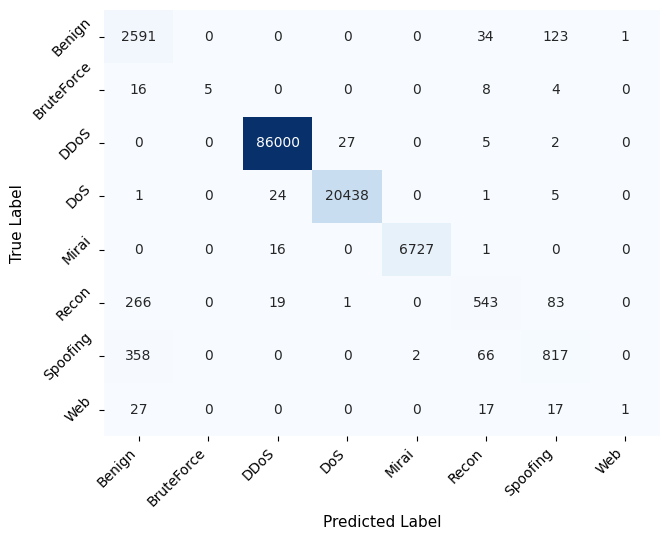

Completed GRU seed 42: test macro F1=0.693767
Saved run results to: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results/GRU_Seed_1

GRU: final run 2/5; seed=43
Epoch 1/100


2026-09-28 10:49:57.608848: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5537/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8196 - loss: 0.4386

2026-09-28 10:50:35.575604: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 44s 7ms/step - accuracy: 0.8390 - loss: 0.3563 - val_accuracy: 0.8880 - val_loss: 0.2515
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9634 - loss: 0.1071 - val_accuracy: 0.9865 - val_loss: 0.0442
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - accuracy: 0.9845 - loss: 0.0495 - val_accuracy: 0.9882 - val_loss: 0.0371
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9862 - loss: 0.0432 - val_accuracy: 0.9881 - val_loss: 0.0355
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9871 - loss: 0.0400 - val_accuracy: 0.9892 - val_loss: 0.0333
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9878 - loss: 0.0377 - val_accuracy: 0.9897 - val_loss: 0.0320
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9880 - loss: 0.0370 - val_accuracy: 0.9895 - val_loss: 0.0318
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9883 - loss: 0.036

2026-09-28 11:22:09.816398: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 11:22:20.164174: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

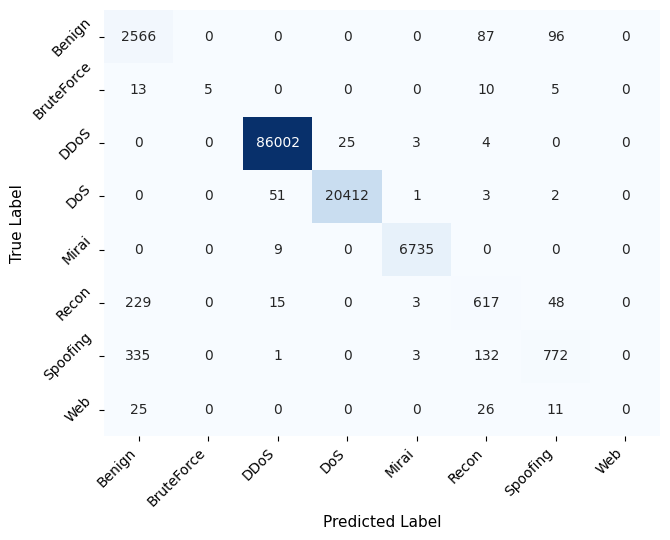

Completed GRU seed 43: test macro F1=0.690585
Saved run results to: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results/GRU_Seed_2

GRU: final run 3/5; seed=44
Epoch 1/100


2026-09-28 11:23:22.209314: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5536/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8214 - loss: 0.4359

2026-09-28 11:23:59.448278: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 43s 7ms/step - accuracy: 0.8410 - loss: 0.3546 - val_accuracy: 0.8782 - val_loss: 0.2704
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9603 - loss: 0.1163 - val_accuracy: 0.9854 - val_loss: 0.0494
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9847 - loss: 0.0509 - val_accuracy: 0.9878 - val_loss: 0.0386
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9867 - loss: 0.0422 - val_accuracy: 0.9883 - val_loss: 0.0357
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9874 - loss: 0.0394 - val_accuracy: 0.9892 - val_loss: 0.0334
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9881 - loss: 0.0370 - val_accuracy: 0.9891 - val_loss: 0.0333
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9881 - loss: 0.0362 - val_accuracy: 0.9898 - val_loss: 0.0318
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9882 - loss: 0.035

2026-09-28 11:46:27.326597: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 11:46:38.136672: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

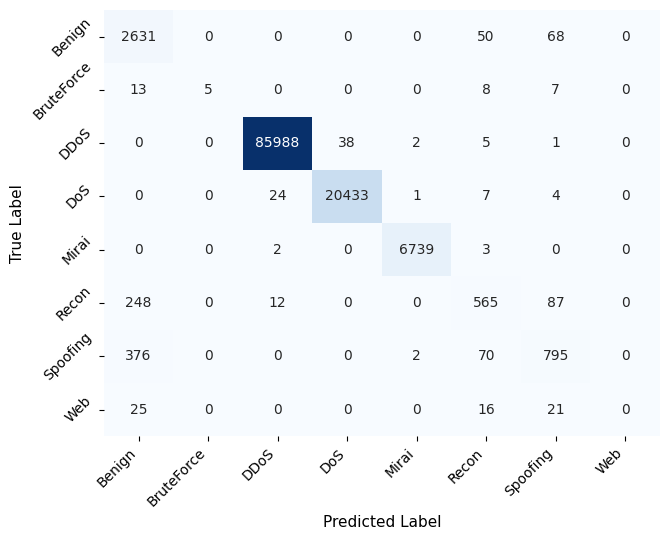

Completed GRU seed 44: test macro F1=0.692002
Saved run results to: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results/GRU_Seed_3

GRU: final run 4/5; seed=45
Epoch 1/100


2026-09-28 11:47:41.422251: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8216 - loss: 0.4319

2026-09-28 11:48:20.067701: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 46s 7ms/step - accuracy: 0.8405 - loss: 0.3529 - val_accuracy: 0.9066 - val_loss: 0.2527
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9642 - loss: 0.1066 - val_accuracy: 0.9869 - val_loss: 0.0503
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9845 - loss: 0.0510 - val_accuracy: 0.9862 - val_loss: 0.0441
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9866 - loss: 0.0435 - val_accuracy: 0.9887 - val_loss: 0.0360
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.9874 - loss: 0.0398 - val_accuracy: 0.9889 - val_loss: 0.0344
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9880 - loss: 0.0375 - val_accuracy: 0.9893 - val_loss: 0.0322
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9880 - loss: 0.0373 - val_accuracy: 0.9893 - val_loss: 0.0328
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9888 - loss: 0.035

2026-09-28 12:16:37.455619: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 12:16:49.338630: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

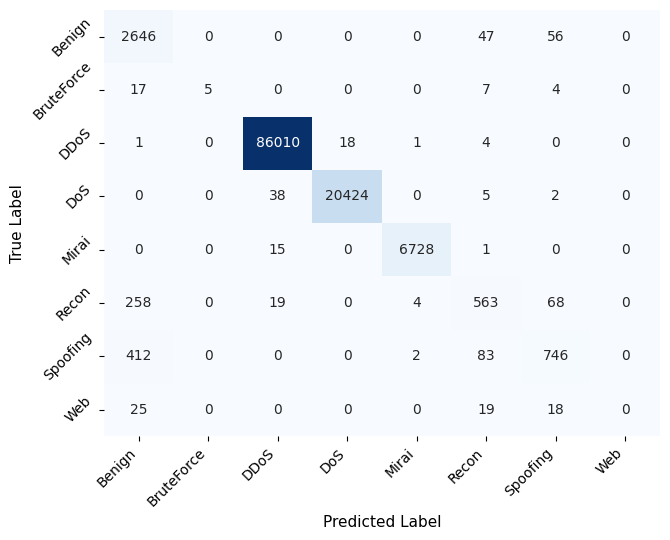

Completed GRU seed 45: test macro F1=0.688763
Saved run results to: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results/GRU_Seed_4

GRU: final run 5/5; seed=46
Epoch 1/100


2026-09-28 12:18:01.720794: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5540/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8216 - loss: 0.4307

2026-09-28 12:18:41.476717: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 47s 8ms/step - accuracy: 0.8394 - loss: 0.3555 - val_accuracy: 0.8770 - val_loss: 0.2913
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - accuracy: 0.9443 - loss: 0.1476 - val_accuracy: 0.9852 - val_loss: 0.0494
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 43s 8ms/step - accuracy: 0.9834 - loss: 0.0543 - val_accuracy: 0.9878 - val_loss: 0.0383
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 47s 9ms/step - accuracy: 0.9862 - loss: 0.0443 - val_accuracy: 0.9888 - val_loss: 0.0348
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 43s 8ms/step - accuracy: 0.9871 - loss: 0.0405 - val_accuracy: 0.9884 - val_loss: 0.0350
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 44s 8ms/step - accuracy: 0.9876 - loss: 0.0379 - val_accuracy: 0.9891 - val_loss: 0.0325
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.9884 - loss: 0.0362 - val_accuracy: 0.9892 - val_loss: 0.0323
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 8ms/step - accuracy: 0.9884 - loss: 0.035

2026-09-28 12:35:44.801997: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 12:35:54.894668: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

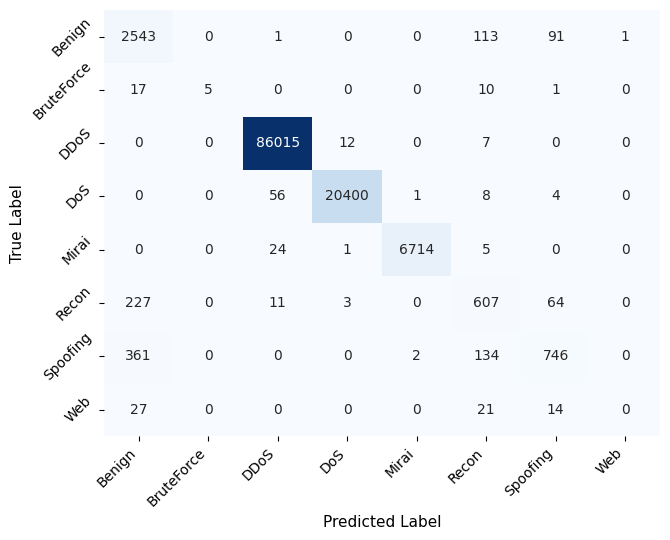

Completed GRU seed 46: test macro F1=0.684305
Saved run results to: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results/GRU_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,GRU,1,42,1464.825862,0.712979,0.030385,0.990494,0.859310,0.669802,0.693767,...,0.990494,0.989908,0.978251,0.997977,0.001382,0.001358,0.001547,9.572035,0.080950,12353.277338
1,GRU,2,43,1932.285809,0.717481,0.030102,0.990384,0.791859,0.672258,0.690585,...,0.990384,0.989847,0.977990,0.997762,0.001442,0.001374,0.001919,9.410794,0.079587,12564.933589
2,GRU,3,44,1385.250801,0.713498,0.029897,0.990782,0.798133,0.670582,0.692002,...,0.990782,0.990169,0.978922,0.997982,0.001288,0.001317,0.001089,9.496642,0.080313,12451.348827
3,GRU,4,45,1736.189268,0.714480,0.030279,0.990494,0.798965,0.665835,0.688763,...,0.990494,0.989801,0.978260,0.997852,0.001417,0.001358,0.001829,10.824201,0.091540,10924.224022
4,GRU,5,46,1063.200277,0.709533,0.030852,0.989716,0.785029,0.666784,0.684305,...,0.989716,0.989192,0.976453,0.997777,0.001569,0.001469,0.002270,8.498007,0.071867,13914.557142


In [19]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    max_epochs,
    batch_size_key,
):
    """Train, evaluate, time, and save the GRU model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            "\n" + "=" * 72
        )
        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )
        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output folder for this independent run.
        # GRU_Seed_1 ... GRU_Seed_10
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"GRU_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()
        set_final_run_seed(seed)

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        history = model.fit(
            X_train_input,
            y_train,
            epochs=max_epochs,
            batch_size=parameters[
                batch_size_key
            ],
            validation_data=(
                X_val_input,
                y_val,
            ),

            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=EARLY_STOPPING_PATIENCE,
                    restore_best_weights=True,
                )
            ],

            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = f1_score(
            y_val,
            validation_predictions,
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
            timing_repetitions,
        ) = benchmark_full_test_prediction(
            model,
            X_test_input,
        )

        # Save the raw full-test timing repetitions used to
        # derive the per-seed inference-time summary.
        pd.DataFrame(
            {
                "Repetition": np.arange(
                    1,
                    len(timing_repetitions) + 1,
                ),
                "Inference_Time_s": timing_repetitions,
                "Latency_ms_per_sample": [
                    value / len(X_test_input) * 1000.0
                    for value in timing_repetitions
                ],
            }
        ).to_csv(
            seed_output_directory
            / "inference_timing_repetitions.csv",
            index=False,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = calculate_test_metrics(
            y_test,
            test_predictions,
            test_probabilities,
            labels,
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "Training_Time_s": float(
                training_time
            ),
            "Validation_F1_macro": float(
                validation_macro_f1
            ),
            "Test_Loss": float(
                evaluation["loss"]
            ),
            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Full classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class Precision / Recall / F1 / FPR
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = precision_recall_fscore_support(
            y_test,
            test_predictions,
            labels=labels,
            zero_division=0,
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = class_confusion_matrices[
                class_index
            ].ravel()

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model": model_name,
                "Run": run_number,
                "Seed": seed,
                "Class": class_name,
                "Precision": float(
                    precision_values[
                        class_index
                    ]
                ),
                "Recall": float(
                    recall_values[
                        class_index
                    ]
                ),
                "F1": float(
                    f1_values[
                        class_index
                    ]
                ),
                "FPR": float(
                    class_fpr
                ),
                "TP": int(
                    true_positive
                ),
                "TN": int(
                    true_negative
                ),
                "FP": int(
                    false_positive
                ),
                "FN": int(
                    false_negative
                ),
                "Support": int(
                    support_values[
                        class_index
                    ]
                ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # FPR summary for this seed
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Run": run_number,
                    "Seed": seed,
                    "FPR_macro": (
                        test_metrics[
                            "FPR_macro"
                        ]
                    ),
                    "FPR_micro_overall": (
                        test_metrics[
                            "FPR_micro_overall"
                        ]
                    ),
                    "FPR_weighted": (
                        test_metrics[
                            "FPR_weighted"
                        ]
                    ),
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )
        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = (
            np.arange(
                1,
                len(history_df) + 1,
            )
        )
        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded": (
                    y_test
                ),
                "Predicted_Label_Encoded": (
                    test_predictions
                ),
                "True_Label": (
                    label_encoder.inverse_transform(
                        y_test
                    )
                ),
                "Predicted_Label": (
                    label_encoder.inverse_transform(
                        test_predictions
                    )
                ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            predictions_df[
                f"Probability_{class_name}"
            ] = test_probabilities[
                :,
                class_index,
            ]

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained model
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"{model_name.lower()}_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save run metadata and exact pre-stored parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "N_Final_Runs": N_FINAL_RUNS,
            "Training_Samples": int(
                len(X_train_input)
            ),
            "Validation_Samples": int(
                len(X_val_input)
            ),
            "Test_Samples": int(
                len(X_test_input)
            ),
            "Hyperparameters": parameters,
            "Ablation_Mode": ABLATION_MODE,
            "Kept_Anomaly_Features": kept_anomaly_features,
            "Dropped_Anomaly_Features": features_to_drop,
            "Warmup_Runs": N_WARMUP_RUNS,
            "Timed_Inference_Repetitions": N_BENCHMARK_RUNS,
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed": seed,
                "Run": run_number,
                "F1_macro": (
                    test_metrics[
                        "F1_macro"
                    ]
                ),
                "Predictions": (
                    test_predictions.copy()
                ),
            }
        )

        print(
            f"Completed {model_name} "
            f"seed {seed}: "
            f"test macro F1="
            f"{test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model
        gc.collect()
        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# GRU-only experiment definition
# Keep the original experiment-definition variable name.
# ============================================================
experiment_definitions = [
    {
        "model_name": "GRU",
        "model_builder": build_final_gru,
        "parameters": best_params_gru_03,
        "X_train_input": X_train_reshaped_GRU,
        "X_val_input": X_val_reshaped_GRU,
        "X_test_input": X_test_reshaped_GRU,
        "max_epochs": MAX_EPOCHS_GRU,
        "batch_size_key": "batch_size_gru",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:
    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )
    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment["model_name"]
    ] = candidates


# Keep the original result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)


### Mean ± sample standard deviation across the ten GRU seeds


In [20]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):
    for metric_name in metric_columns:
        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model": model_name,
                "Metric": metric_name,
                "Mean": metric_mean,
                "SD": metric_sd,
                "N": int(
                    metric_values
                    .notna()
                    .sum()
                ),
                "Mean ± SD": format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
            }
        )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long.pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(["GRU"])
)


# Backward-compatible aliases for downstream code that used the
# original five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)
five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run GRU journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_macro,0.806659,0.029962,5,0.806659 ± 0.029962
1,GRU,Recall_macro,0.669052,0.002677,5,0.669052 ± 0.002677
2,GRU,F1_macro,0.689884,0.003621,5,0.689884 ± 0.003621
3,GRU,ROC_AUC_macro_OvR,0.997870,0.000105,5,0.997870 ± 0.000105
4,GRU,FPR_macro,0.001420,0.000102,5,0.001420 ± 0.000102


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_weighted,0.990077,0.000422,5,0.990077 ± 0.000422
1,GRU,Recall_weighted,0.990374,0.000396,5,0.990374 ± 0.000396
2,GRU,F1_weighted,0.989783,0.000360,5,0.989783 ± 0.000360
3,GRU,FPR_weighted,0.001731,0.000442,5,0.001731 ± 0.000442


Five-run GRU journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
GRU,0.990374 ± 0.000396,0.689884 ± 0.003621,0.989783 ± 0.000360,0.001420 ± 0.000102,0.001375 ± 0.000057,0.001731 ± 0.000442,9.560336 ± 0.829526,0.080851 ± 0.007015,0.977975 ± 0.000918,0.806659 ± 0.029962,0.990077 ± 0.000422,0.997870 ± 0.000105,0.669052 ± 0.002677,0.990374 ± 0.000396,0.030303 ± 0.000358,12441.668184 ± 1060.087223,1516.350403 ± 334.110128,0.713594 ± 0.002862


### Per-class mean ± sample standard deviation

FPR is included together with Precision, Recall, and F1.


In [21]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        ["Model", "Class"],
        sort=False,
    )
):
    record = {
        "Model": model_name,
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(ddof=1)
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Keep the original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,GRU,Benign,2749,5,0.798530,0.008152,0.798530 ± 0.008152,0.944125,0.015707,0.944125 ± 0.015707,0.865140,0.004745,0.865140 ± 0.004745,0.005675,0.000360,0.005675 ± 0.000360
1,GRU,BruteForce,33,5,1.000000,0.000000,1.000000 ± 0.000000,0.151515,0.000000,0.151515 ± 0.000000,0.263158,0.000000,0.263158 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000
2,GRU,DDoS,86034,5,0.999217,0.000235,0.999217 ± 0.000235,0.999640,0.000120,0.999640 ± 0.000120,0.999428,0.000064,0.999428 ± 0.000064,0.002092,0.000628,0.002092 ± 0.000628
3,GRU,DoS,20469,5,0.998778,0.000428,0.998778 ± 0.000428,0.997675,0.000758,0.997675 ± 0.000758,0.998226,0.000280,0.998226 ± 0.000280,0.000256,0.000090,0.000256 ± 0.000090
4,GRU,Mirai,6744,5,0.999199,0.000475,0.999199 ± 0.000475,0.997716,0.001417,0.997716 ± 0.001417,0.998456,0.000619,0.998456 ± 0.000619,0.000048,0.000029,0.000048 ± 0.000029
5,GRU,Recon,912,5,0.745955,0.056786,0.745955 ± 0.056786,0.634868,0.034570,0.634868 ± 0.034570,0.683664,0.009027,0.683664 ± 0.009027,0.001734,0.000615,0.001734 ± 0.000615
6,GRU,Spoofing,1243,5,0.811596,0.021950,0.811596 ± 0.021950,0.623652,0.024975,0.623652 ± 0.024975,0.704754,0.010430,0.704754 ± 0.010430,0.001549,0.000282,0.001549 ± 0.000282
7,GRU,Web,62,5,0.100000,0.223607,0.100000 ± 0.223607,0.003226,0.007213,0.003226 ± 0.007213,0.006250,0.013975,0.006250 ± 0.013975,0.000003,0.000005,0.000003 ± 0.000005


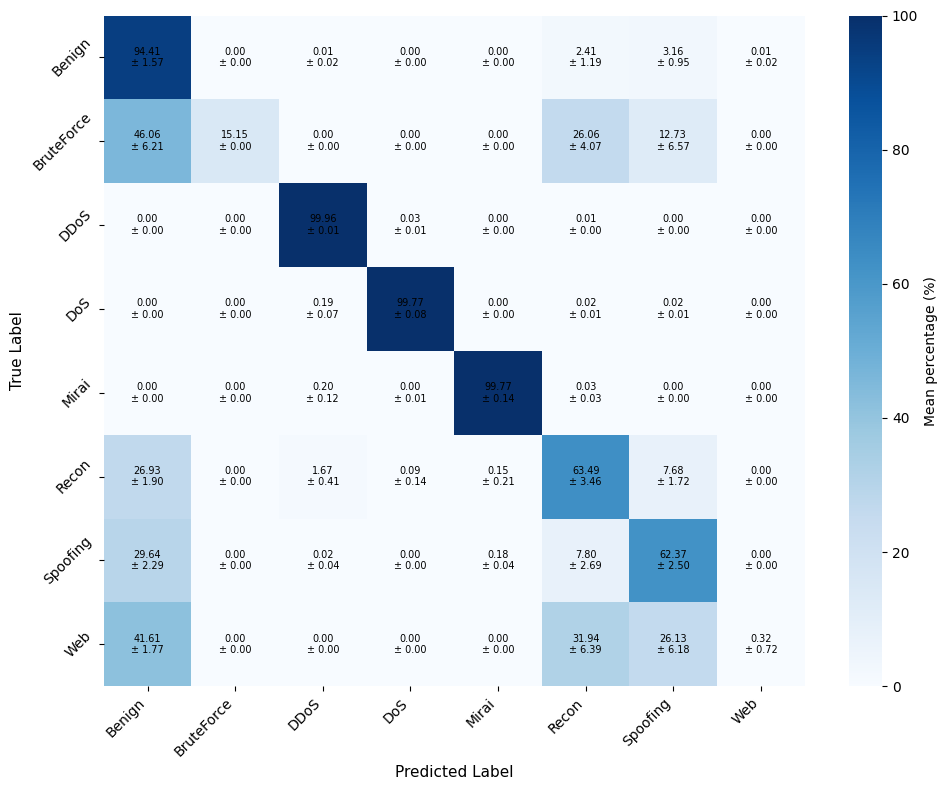

Saved the five-seed GRU normalized confusion matrix mean ± sample SD.


In [22]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# ============================================================

# One final matrix is produced. Individual seed matrices are
# calculated internally only to obtain the across-seed mean
# and sample standard deviation for each matrix cell.

labels = np.arange(number_of_classes)
class_names = label_encoder.classes_

normalized_confusion_matrices = []

# ------------------------------------------------------------
# Build one row-normalized confusion matrix per seed
# ------------------------------------------------------------
for candidate in representative_candidates_by_model["GRU"]:

    seed_predictions = candidate[
        "Predictions"
    ]

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,
        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),
        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )

normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)

if normalized_confusion_matrices.shape[0] != len(RUN_SEEDS):
    raise ValueError(
        "The number of confusion matrices does not match "
        "the number of final-run seeds."
    )

# ------------------------------------------------------------
# Cell-wise mean and sample SD across the five seeds
# ------------------------------------------------------------
mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,
)

# Convert proportions to percentages.
mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0

# ------------------------------------------------------------
# Save numerical mean and SD matrices
# ------------------------------------------------------------
mean_cm_df = pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
)

sd_cm_df = pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
)

mean_cm_df.index.name = "True_Label"
mean_cm_df.columns.name = "Predicted_Label"

sd_cm_df.index.name = "True_Label"
sd_cm_df.columns.name = "Predicted_Label"

mean_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean.csv"
)

sd_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_sd.csv"
)

# ------------------------------------------------------------
# Save a combined mean ± SD table
# ------------------------------------------------------------
mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        mean_sd_table.iloc[i, j] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )

mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"

mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.csv"
)

# ------------------------------------------------------------
# Plot ONE final mean ± SD normalized confusion matrix
# ------------------------------------------------------------
plt.figure(
    figsize=(10, 8)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        ax.text(
            j + 0.5,
            i + 0.5,
            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),
            ha="center",
            va="center",
            fontsize=7,
        )

plt.xlabel(
    "Predicted Label",
    fontsize=11,
)

plt.ylabel(
    "True Label",
    fontsize=11,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved the five-seed GRU normalized confusion "
    "matrix mean ± sample SD."
)


### Representative GRU confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run GRU mean. This follows the selection principle used in the original
five-run code.


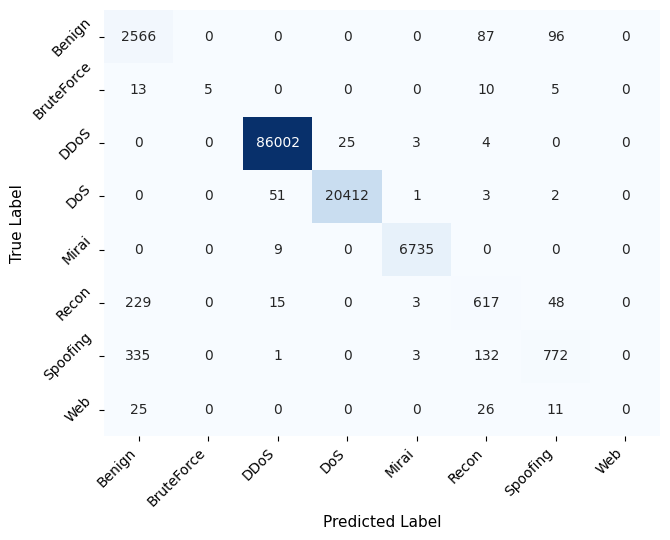

,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,GRU,2,43,0.690585,0.689884


All five-run GRU outputs were saved:


In [23]:
representative_run_records = []


for model_name in ["GRU"]:
    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item["F1_macro"]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model": model_name,
            "Representative_Run": (
                representative["Run"]
            ),
            "Representative_Seed": (
                representative["Seed"]
            ),
            "Representative_F1_macro": (
                representative[
                    "F1_macro"
                ]
            ),
            "Five_Run_Mean_F1_macro": (
                model_mean_f1
            ),
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_classification_report.csv"
        )
    )


# Keep the original result-variable name.
representative_runs = pd.DataFrame(
    representative_run_records
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run GRU outputs were saved:"
)


In [ ]:
# ============================================================
# Offline classifier-only inference timing from saved GRU models
# ============================================================

# This benchmark can be rerun later without retraining.
# It loads the exact saved test tensor and each saved .keras model.
#
# Timing definition:
# - classifier prediction only,
# - preprocessing excluded,
# - model loading excluded,
# - 3 warm-up predictions,
# - 5 timed full-test predictions per independently trained seed.

OFFLINE_WARMUP_RUNS = 3
OFFLINE_TIMING_REPETITIONS = 5

offline_X_test = np.load(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy"
)

offline_timing_rows = []
offline_seed_summary_rows = []

for run_number, seed in enumerate(
    RUN_SEEDS,
    start=1,
):

    model_path = (
        REPORT_OUTPUT_DIRECTORY
        / f"GRU_Seed_{run_number}"
        / f"gru_seed_{seed}.keras"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Saved GRU model not found: {model_path}"
        )

    # Model loading is intentionally outside the timed region.
    offline_model = tf.keras.models.load_model(
        model_path,
        compile=False,
    )

    warmup_size = min(
        1024,
        len(offline_X_test),
    )

    for _ in range(
        OFFLINE_WARMUP_RUNS
    ):
        offline_model.predict(
            offline_X_test[
                :warmup_size
            ],
            verbose=0,
        )

    seed_times = []

    for repetition in range(
        1,
        OFFLINE_TIMING_REPETITIONS + 1,
    ):

        start_time = time.perf_counter()

        offline_model.predict(
            offline_X_test,
            verbose=0,
        )

        elapsed_time = (
            time.perf_counter()
            - start_time
        )

        seed_times.append(
            elapsed_time
        )

        offline_timing_rows.append(
            {
                "Run": run_number,
                "Seed": seed,
                "Repetition": repetition,
                "Inference_Time_s": elapsed_time,
                "Latency_ms_per_sample": (
                    elapsed_time
                    / len(offline_X_test)
                    * 1000.0
                ),
                "Throughput_samples_per_s": (
                    len(offline_X_test)
                    / elapsed_time
                ),
            }
        )

    seed_mean_time = float(
        np.mean(seed_times)
    )

    seed_sd_time = float(
        np.std(
            seed_times,
            ddof=1,
        )
    )

    offline_seed_summary_rows.append(
        {
            "Run": run_number,
            "Seed": seed,
            "Mean_Inference_Time_s": seed_mean_time,
            "SD_Inference_Time_s": seed_sd_time,
            "Mean_Latency_ms_per_sample": (
                seed_mean_time
                / len(offline_X_test)
                * 1000.0
            ),
            "Mean_Throughput_samples_per_s": (
                len(offline_X_test)
                / seed_mean_time
            ),
        }
    )

    del offline_model
    gc.collect()
    tf.keras.backend.clear_session()


# ------------------------------------------------------------
# Save repetition-level and per-seed timing results
# ------------------------------------------------------------
offline_timing_repetitions_df = pd.DataFrame(
    offline_timing_rows
)

offline_timing_per_seed_df = pd.DataFrame(
    offline_seed_summary_rows
)

offline_timing_repetitions_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_repetitions.csv",
    index=False,
)

offline_timing_per_seed_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_per_seed.csv",
    index=False,
)


# ------------------------------------------------------------
# Five-seed mean ± sample SD
# ------------------------------------------------------------

seed_mean_times = (
    offline_timing_per_seed_df[
        "Mean_Inference_Time_s"
    ].to_numpy(
        dtype=float
    )
)

seed_mean_latencies = (
    offline_timing_per_seed_df[
        "Mean_Latency_ms_per_sample"
    ].to_numpy(
        dtype=float
    )
)

seed_mean_throughputs = (
    offline_timing_per_seed_df[
        "Mean_Throughput_samples_per_s"
    ].to_numpy(
        dtype=float
    )
)

offline_summary_df = pd.DataFrame(
    [
        {
            "Metric": "Inference_Time_s",
            "Mean": float(
                np.mean(
                    seed_mean_times
                )
            ),
            "SD": float(
                np.std(
                    seed_mean_times,
                    ddof=1,
                )
            ),
            "N_Seeds": len(
                RUN_SEEDS
            ),
        },
        {
            "Metric": "Latency_ms_per_sample",
            "Mean": float(
                np.mean(
                    seed_mean_latencies
                )
            ),
            "SD": float(
                np.std(
                    seed_mean_latencies,
                    ddof=1,
                )
            ),
            "N_Seeds": len(
                RUN_SEEDS
            ),
        },
        {
            "Metric": "Throughput_samples_per_s",
            "Mean": float(
                np.mean(
                    seed_mean_throughputs
                )
            ),
            "SD": float(
                np.std(
                    seed_mean_throughputs,
                    ddof=1,
                )
            ),
            "N_Seeds": len(
                RUN_SEEDS
            ),
        },
    ]
)

offline_summary_df[
    "Mean ± SD"
] = offline_summary_df.apply(
    lambda row: (
        f"{row['Mean']:.6f} ± "
        f"{row['SD']:.6f}"
    ),
    axis=1,
)

offline_summary_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_summary.csv",
    index=False,
)

print(
    "Offline GRU inference timing completed."
)

display(
    offline_timing_per_seed_df
)

display(
    offline_summary_df
)


In [24]:
import shutil

# Compress the active ablation-mode result directory only.
archive_base = (
    Path("/kaggle/working")
    / f"CICIoT2023_{ABLATION_MODE}_GRU_5_seed_results"
)

shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=REPORT_OUTPUT_DIRECTORY,
)

print(
    "Created:",
    f"{archive_base}.zip",
)


Created: /kaggle/working/CICIoT2023_No_FA_GRU_5_seed_results.zip
